## 회귀 모델(알고리즘)
- 회귀 : 연속적인 수치(숫자)를 예측하는 모델
- 분류 vs 회귀
    - 분류 : 범주(up/down)을 예측하며, 예측이 맞았는지/틀렸는지가 명확함 (혼동행렬, 정확도 등)
    - 회귀 : 연속적인 수치(수익률)을 예측하며, 정확히 맞았다는 개념이 없음! -> 오차의 크기를 측정
    (MAEm RMSE, R^2 등)
> **회귀에서는 얼마나 가까운가(오차의 크기)**가 가장 중요!\
> 참고: **로지스틱 회귀**는 이름만 회귀이고, 성형 계산 후 확률을 통해 범주를 판단하는 **분류 모델**임! 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from _ml import build_dataset, time_split, FEATURES, SEED
from _style import setup

setup()
pd.set_option("display.width", 130)

df = build_dataset()
train, test, cutoff = time_split(df)

tr = train.sample(15000, random_state=SEED)
te = test.sample(4000, random_state=SEED)

X_train, X_test = tr[FEATURES], te[FEATURES]

# 정답(y)을 두 종류 준비 -> 분류(target_up) / 회귀(target_ret)
y_train_cls, y_test_cls = tr["target_up"], te["target_up"]  # 분류용 정답 : 상승(1) / 하락(0)
y_train_reg, y_test_reg = tr["target_ret"], te["target_ret"]# 회귀용 정답 : 수익률(수치)

print(f" * 학습 {len(tr):,}행 ({tr['date'].min().date()} ~ {tr['date'].max().date()})")
print(f" * 테스트 {len(te):,}행 ({te['date'].min().date()} ~ {te['date'].max().date()})")
print(f" * 피처 {len(FEATURES)}개")
print()
print(f" - 분류용 정답(target_up) : {y_train_cls.unique()} (범주)")
print(f" - 회귀용 정답(target_ret) : {y_train_reg.min():.4f} ~ {y_train_reg.max():.4f}")

 * 학습 15,000행 (2023-10-24 ~ 2026-01-16)
 * 테스트 4,000행 (2026-01-19 ~ 2026-09-07)
 * 피처 7개

 - 분류용 정답(target_up) : [0 1] (범주)
 - 회귀용 정답(target_ret) : -0.2260 ~ 0.2313


 - 분류 : y = target_up(0/1) --> RandomForesetClassifier
 - 회귀 : y = targt_ret(수익률) --> RandomForestRegressor

 **이름은 동일한 알고리즘이지만, 평가 방법이 완전히 달라짐!**
 - RandomForestClassifier => accuracy_score(정확도), f1_score(f1 점수)
 - RandomForestRegressor => mean_absolute_error(MAE), mean_squared_error(MSE), r2_score(R^2)

In [2]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from sklearn.metrics import (accuracy_score, f1_score,                              # 분류 평가지표
                              mean_absolute_error, mean_squared_error, r2_score)    # 회귀 평가지표

clf = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=SEED, n_jobs=-1)
reg = RandomForestRegressor(n_estimators=100, max_depth=6, random_state=SEED, n_jobs=-1)

# 학습 --> fit(X, y)
# 분류 모델 학습
clf.fit(X_train, y_train_cls)

# 회귀 모델 학습
reg.fit(X_train, y_train_reg)

# 예측 --> predict(X)
# 분류 모델 예측 (pred_cls)
pred_cls = clf.predict(X_test)

# 회귀 모델 예측 (pred_reg)
pred_reg = reg.predict(X_test)

print(f"{'':<14}{'분류':<32}{'회귀'}")
print("-" * 70)
print(f"{'정답예시':<13}{y_test_cls.iloc[0]:<32}{y_test_reg.iloc[0]:.4f}")
print(f"{'예측예시':<13}{pred_cls[0]:<32}{pred_reg[0]:.4f}")
print()
print(f"분류 평가 : 정확도 {accuracy_score(y_test_cls, pred_cls):.4f}"
      f"    F1 {f1_score(y_test_cls, pred_cls):.4f}")

print(f"회귀 평가 : RMSE { np.sqrt(mean_squared_error(y_test_reg, pred_reg)):.6f}"
      f"    R^2 {r2_score(y_test_reg, pred_reg):.4f}")

              분류                              회귀
----------------------------------------------------------------------
정답예시         0                               -0.0068
예측예시         1                               -0.0000

분류 평가 : 정확도 0.4933    F1 0.4269
회귀 평가 : RMSE 0.027389    R^2 -0.0068


In [3]:
# 회귀 예측을 0 기준으로 나누어서 분류를 해본다면?
reg_to_cls = (pred_reg > 0).astype(int)

print(f"회귀 모델 예측을 0 기준으로 나눈 정확도: "
      f" {accuracy_score(y_test_cls, reg_to_cls):.4f}")
print(f"분류 모델로 학습한 정확도: "
      f" {accuracy_score(y_test_cls, pred_cls):.4f}")

회귀 모델 예측을 0 기준으로 나눈 정확도:  0.4793
분류 모델로 학습한 정확도:  0.4933


---
## LinearRegression (선형 회귀)
가장 단순한 선형 회귀 모델. 직선으로 관계를 표현.
`예측값 = w1*X + w2*X + ... + b`

- 학습 : **오차의 제곱합(MSE)**이 가장 작아지는 가중치(W)와 절편(b)를 찾는 것.
    - w - 가중치(계수) : 다른 피처가 그대로일 때, 해당 피처가 1 증가하면 예측값이 얼마나 변하는지
    - b 절편(편향)

In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler    # 각 피처의 평균 0, 표준편차 1로 맞춰줌

def make(model):
    return Pipeline([("sc", StandardScaler()), ("m",model)])

lin = make(LinearRegression())

lin.fit(X_train, y_train_reg)

# 절편(b), 계수(w) 확인
coef = pd.Series(lin.named_steps["m"].coef_, index=FEATURES).sort_values()
# lin.named_steps["m"] : 모델 객체 추출
# 모델.coef_ : 가중치(개수) 배열

intercept = lin.named_steps["m"].intercept_
# 모델.intercept_ : 절편(편향) 값

print(f" * 절편 (b) : {intercept:.6f}")
print()
print(f" * 가중치 (w) :")
print(coef.round(6).to_string())

 * 절편 (b) : -0.000063

 * 가중치 (w) :
vol20          -0.000567
ma20_ratio     -0.000507
volume_ratio   -0.000161
range_pct       0.000055
ma5_ratio       0.000117
ret_5d          0.000544
ret_1d          0.000756


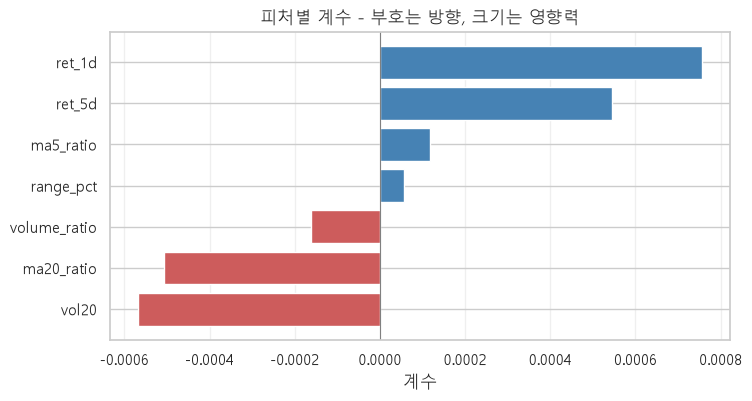

In [5]:
fig, ax = plt.subplots(figsize=(8,4))

colors = ["indianred" if v < 0 else "steelblue" for v in coef.values]

ax.barh(coef.index, coef.values, color=colors)

ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel("계수")
ax.set_title("피처별 계수 - 부호는 방향, 크기는 영향력")
ax.grid(alpha=0.3, axis="x")

plt.show()

**계수(가중치)는 해석을 도와주는 지표**
계수의 부호는 방향 (+ 올리는 쪽/- 내리는 쪽)을, 절대값은 영향력의 크기를 알려줌\
다만, 피처의 스케일(단위)이 다르면 계수 크기를 직접 비교할 수 없으므로 **스케일링을 먼저** 진행해야 함

또한 피처끼리 서로 비슷하다면(다중 공선성) 계수가 불안정해져서 해석이 틀어질 수 있음. \
(우리 데이터의 계수는 모두 0에 가까운 아주 작은 값이므로, 선형 관계가 거의 없다고 볼 수 있음)

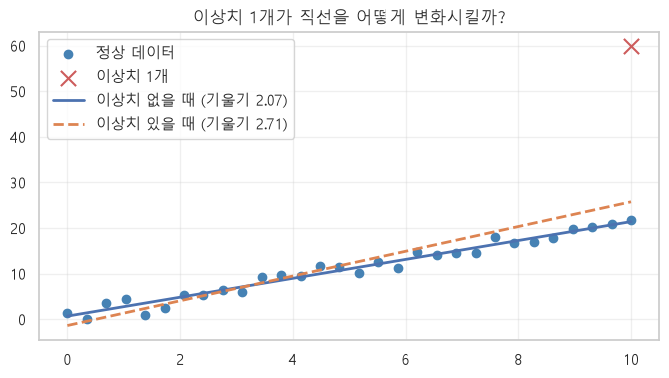

In [6]:
# 이상치 하나 넣어서 직선의 변화를 확인해보기

rng = np.random.default_rng(SEED)   # 난수 생성기

x_demo = np.linspace(0, 10, 30) # 0 ~ 10 구간을 균등하게 나눈 30개의 숫자
# y = 2x + 1
y_demo = 2 * x_demo + 1 + rng.normal(0, 1.5, 30)

# 이상치 1개 추가 : x=10 y =60 (원래대로라면 21 근처 값이어야 함)
x_bad = np.append(x_demo, 10)
y_bad = np.append(y_demo, 60)

fig, ax = plt.subplots(figsize=(8,4))

ax.scatter(x_demo, y_demo, label="정상 데이터", color="steelblue")
ax.scatter([10], [60], s=120, label="이상치 1개", color="indianred", marker="x", zorder=5)

datas = [
    (x_demo, y_demo, "-", "이상치 없을 때"),
    (x_bad, y_bad, "--", "이상치 있을 때")
]

for xs, ys, d, name in datas:
    m = LinearRegression().fit(xs.reshape(-1, 1), ys)

    xx = np.linspace(0, 10, 10)
    ax.plot(xx, m.predict(xx.reshape(-1,1)), d, lw=2, label=f"{name} (기울기 {m.coef_[0]:.2f})")

ax.legend()
ax.grid(alpha=0.3)
ax.set_title("이상치 1개가 직선을 어떻게 변화시킬까?")

plt.show()

**이상치 하나가 직선을 끌고가는 것을 확일할 수 있음**

선형 회귀는 오차의 제곱을 최소화함. 크게 빗나간 데이터(이상치)가 제곱되면서 영향력이 매우 커짐!

---

## 규제 회귀 - Ridge, Lasso, ElasticNet

피처가 많아지면 모델이 학습 데이터의 잡음까지 외우게 되고, 계수가 비정상적으로 커지면서
과적합이 일어나게 됨. \
규제는 **계수가 커지는 것에 벌점**을 줘서 이를 막는 방법.

`비용 = 오차(MSE) + 벌점` (절편 b는 벌점 대상이 아님)

|| Ridge(L2) | Lasso(L1) | ElasticNet |
|:--:|:--:|:--:|:--:|
|벌점|계수의 제곱합|계수의 절댓값 합|둘을 섞음 (`l1_ratio`로 비율 조절)|
|효과|계수를 골고루 작게|덜 중요한 계수를 0으로|중간|
|결과|모든 피처 유지(0이 되지 않음)|피처 선택|상관된 피처가 많을 때 유용|

> **주의** : 동일한 `alpha`을 사용한다고 해서, Ridge와 Lasso의 규제 세기가 동일하지 않음(내부 구현 오차 항 배율이 다름)

In [7]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet

models = {
    "Linear": make(LinearRegression()), # 규제가 없는 기본 선형 회귀
    "Ridge(a=1)": make(Ridge(alpha=1.0)),    # 규제가 약한 Ridge => 계수를 조금 줄인 모델
    "Ridge(a=1000)": make(Ridge(alpha=1000.0)), # 규제가 강한 Ridge => 계수를 많이 줄인 모델
    "Lasso(alpha=1e-4)": make(Lasso(alpha=1e-4)),   # 규제가 약한 Lasso => 일부 계수만 0
    "Lasso(alpha=1e-3)": make(Lasso(alpha=1e-3)),   # 규제가 강한 Lasso => 불필요한 계수를 0
    "ElasticNet": make(ElasticNet(alpha=1e-4, l1_ratio=0.5)) # l1_ratio=0.5 : Lasso와 Ridge 벌점을 반반
}

coef_table = {}

for name, m in models.items():
    m.fit(X_train, y_train_reg)
    coef_table[name] = m.named_steps["m"].coef_

coef_df = pd.DataFrame(coef_table, index=FEATURES)
print(coef_df.round(6).to_string())

for col in ["Lasso(alpha=1e-4)", "Lasso(alpha=1e-3)"]:
    zero_features = [f for f, v in coef_df[col].items() if v == 0]
    print(f"{col:<20} 0이 된 피처 ({len(zero_features)}개) : {zero_features}")

                Linear  Ridge(a=1)  Ridge(a=1000)  Lasso(alpha=1e-4)  Lasso(alpha=1e-3)  ElasticNet
ret_1d        0.000756    0.000756       0.000657           0.000659                0.0    0.000707
ret_5d        0.000544    0.000544       0.000380           0.000132                0.0    0.000339
ma5_ratio     0.000117    0.000117       0.000235           0.000133                0.0    0.000124
ma20_ratio   -0.000507   -0.000506      -0.000392          -0.000058                0.0   -0.000282
vol20        -0.000567   -0.000567      -0.000528          -0.000460                0.0   -0.000510
volume_ratio -0.000161   -0.000161      -0.000151          -0.000058                0.0   -0.000107
range_pct     0.000055    0.000055       0.000046           0.000000                0.0    0.000000
Lasso(alpha=1e-4)    0이 된 피처 (1개) : ['range_pct']
Lasso(alpha=1e-3)    0이 된 피처 (7개) : ['ret_1d', 'ret_5d', 'ma5_ratio', 'ma20_ratio', 'vol20', 'volume_ratio', 'range_pct']


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], 

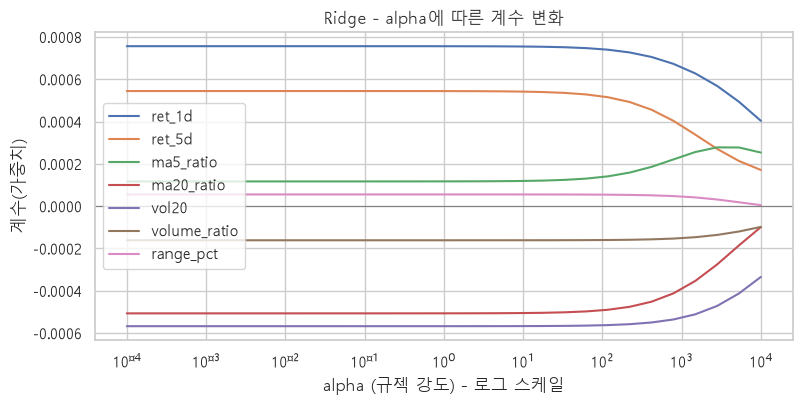

In [8]:
# alpha을 키우면 계수가 어떻게 줄어드는지 확인해보기

# 0.0001 ~ 10000 구간을 로그 스케일 간격으로 30개로 나눔
alphas = np.logspace(-4, 4, 30)

path = []

for a in alphas:
    m = make(Ridge(alpha=a))

    m.fit(X_train, y_train_reg)
    path.append(m.named_steps["m"].coef_)

path = np.array(path)

fig, ax = plt.subplots(figsize=(9,4))
for i, f in enumerate(FEATURES):
    ax.plot(alphas, path[:, i], label=f)

ax.set_xscale("log")
ax.axhline(0, color="gray", lw=0.8)

ax.set_xlabel("alpha (규젝 강도) - 로그 스케일")
ax.set_ylabel("계수(가중치)")
ax.set_title("Ridge - alpha에 따른 계수 변화")

ax.legend()

plt.show()

**alpha(규제 강도)를 너무 키우면 과소적합이 됨.**

규제가 강해질수록 계수가 전부 0에 가까워지고, 모델은 사실상 아무것도 학습하지 못함.
(그래프에서도 계수가 0으로 수렴함)

적절한 alpha값은 데이터마다 다름.

**Lasso는 피처를 골라줌**
불필요한 피처의 계수를 아예 0으로 만들어 모델에서 제외함.
위 표에서 alpha = 1e-4일 때는 `range_pct` 1개만 제외되었지만,\
alpha=1e-3일 때는 7개의 피처가 모두 제외됨.

이번 데이터 기준으로 alpha=1e-3부터는 규제가 너무 강해서 "아무것도 쓰지 못하고 평균만 예측하는 모델"이 되었음!
**alpha값은 타깃(y)과 계수의 크기에 맞춰서 정해야 함.**
(수익률처럼 y값이 아주 작은 데이터는 alpha값도 작게 잡아야 함.)

---
## KNN 회귀와 RandomForest 회귀

### KNN
> **KNeighborsClassifier** -> 주변 k개의 **다수결**로 범주 결정
> **KneighborsRegressor** -> 주변 k의 **평균**으로 수치 결정

### RandomForest
> **RandomForestClassifier** -> 트리들의 다수결
> **RandomForestRegressor** -> 트리들의 예측값의 **평균**

스케일링은 거리 기반 KNN에게 필요하고, 트리 계열은 필요 없음!

In [9]:
from sklearn.neighbors import KNeighborsRegressor

models = {
    "기본값(평균)": None,
    "Linear": make(LinearRegression()),
    "Ridge(a=1.0)": make(Ridge(alpha=1.0)),
    "Lasso(a=1e-4)": make(Lasso(alpha=1e-4)),
    "KNN(k=50)": make(KNeighborsRegressor(n_neighbors=50, n_jobs=-1)),
    "RandomForest": RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=SEED, max_depth=6) 
}

rows = []   # 모델별 평가 지표
preds = {}  # 모델별 예측 결과

for name, m in models.items():
    if m is None:
        # 학습 데이터의 평균만으로 직접 예측 (비교 기준선)
        p = np.full(len(y_test_reg), y_train_reg.mean())
        r2_train = 0.0
    else:
        m.fit(X_train, y_train_reg)
        
        p = m.predict(X_test)
        r2_train = m.score(X_train, y_train_reg) # 회귀모델에서는 R^2 반환 (학습 데이터 기준)

    preds[name] = p
    rows.append({
        "모델": name,
        "MAE": mean_absolute_error(y_test_reg, p),
        "RMSE": np.sqrt(mean_squared_error(y_test_reg, p)),
        "R^2 (테스트)": r2_score(y_test_reg, p),
        "R^2 (학습)": r2_train
    })

print(pd.DataFrame(rows).round(6).to_string(index=False))

           모델      MAE     RMSE  R^2 (테스트)  R^2 (학습)
      기본값(평균) 0.017888 0.027297  -0.000001  0.000000
       Linear 0.017925 0.027317  -0.001506  0.001950
 Ridge(a=1.0) 0.017925 0.027317  -0.001506  0.001950
Lasso(a=1e-4) 0.017922 0.027313  -0.001204  0.001777
    KNN(k=50) 0.018125 0.027621  -0.023880  0.024733
 RandomForest 0.017967 0.027389  -0.006779  0.051433


### R^2 = 1 - (모델의 오차 제곱합) / (평균으로 예측했을 때의 오차 제곱 합)

| R^2 | 의미 |
|:--:|:--:|
| 1.0 | 완벽 |
| 0.7 | 타깃 변동(분산)의 70% |
| 0.0 | 평균으로 찍은 것과 동일 |
| 음수 | 평균으로 찍은 것보다 좋지 않음 |

평균을 예측한 결과를 기준으로 **다른 모델이 이 기준선보다 좋은지** 를 판단해야함.\

위의 결과를 보면 이번 데이터에서는 어떤 모델도 평균 기준선보다 좋은 지표를 만들지 못함! (R^2 테스트 기준)

또한, 랜덤 포레스트는 학습 R^2보다 굉장히 높아서, 학습 데이터의 잡음을 일부 외운 **과적합** 신호로 볼 수 있음.

---
## 평가 지표 - MAE, MSE, RMSE, R^2
회귀 모델의 평가 지표는 모두 **오차(실제값-예측값)** 를 가지고 구한 값들이다.

- MAE : 오차 절대값의 평균. 해석이 직관적이고, 이상치에 덜 민감
- MSE : 오차 제곱의 평균. 큰 오차에 큰 벌점, 단위가 제곱이라 해석이 어려움
- RMSE : MSE의 제곱근. MSE의 장점 + 기존 단위로 해석 가능
- R^2 : 평균으로 찍을 때 대비 모델 점수. 단위가 없어서 모델간 비교 시 유용

> 결과 보고 시에, **MAE** , **RMSE**, **R^2** 지표들로 함께 보고하자.\
> R^2 는 단위가 없기 때문에 같은 데이터에서 모델끼리 비교하기는 좋지만, 얼마만큼 차이가 있는지는 설명하기가 어려움.
--- 

## 잔차 분석
`residual = y_test - pred`

In [10]:
pred_rf = preds["RandomForest"]
residual = y_test_reg.values - pred_rf

print("잔차 = 실제값 - 예측값")
print(f"  * 평균 : {residual.mean():>12.6f}")
print(f"  * 표준편차 : {residual.std():>12.6f}")
print(f"  * 최대 : {residual.max():>12.6f}")
print(f"  * 최소 : {residual.min():>12.6f}")

잔차 = 실제값 - 예측값
  * 평균 :     0.000095
  * 표준편차 :     0.027389
  * 최대 :     0.205061
  * 최소 :    -0.204308


> 잔차 평균이 0에 가깝다는 것은 어느 한쪽으로 쏠려서 예측하지는 않았다는 것을 의미함.\
> 다만, 평균이 0이라고 해서 잘 맞추는 모델을 의미하지는 않음!

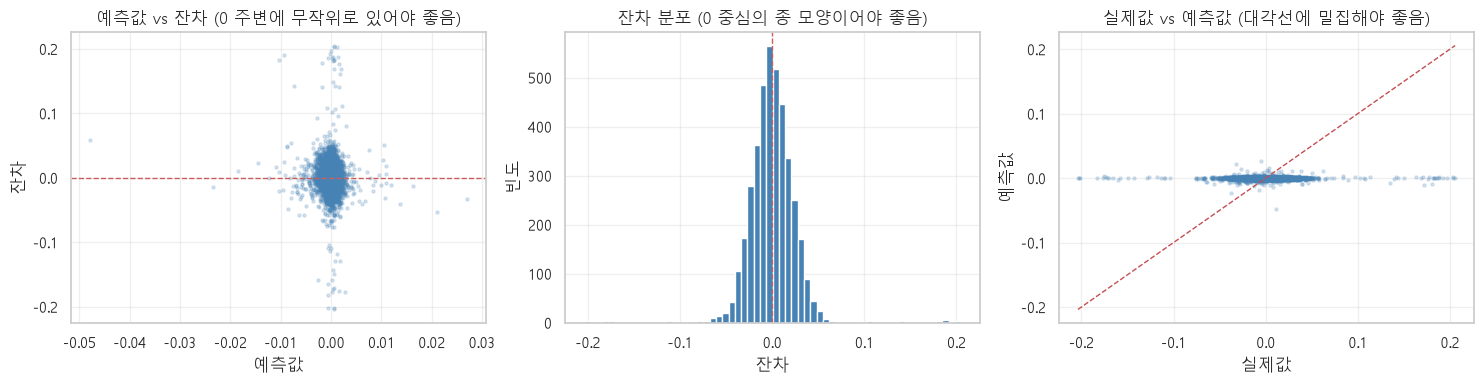

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))

# 1. 예측값 vs 잔차
axes[0].scatter(pred_rf, residual, s=5, alpha=0.2, color='steelblue')
axes[0].axhline(0, color='indianred', ls='--', lw=1)

axes[0].set_xlabel("예측값")
axes[0].set_ylabel("잔차")
axes[0].set_title("예측값 vs 잔차 (0 주변에 무작위로 있어야 좋음)")
axes[0].grid(alpha=0.3)

# 2. 잔차 히스토그램
axes[1].hist(residual, bins=60, color='steelblue')
axes[1].axvline(0, color='indianred', ls='--', lw=1)

axes[1].set_xlabel("잔차")
axes[1].set_ylabel("빈도")
axes[1].set_title("잔차 분포 (0 중심의 종 모양이어야 좋음)")
axes[1].grid(alpha=0.3)

# 3. 실제값 vs 예측값
axes[2].scatter(y_test_reg, pred_rf, s=5, alpha=0.2, color='steelblue')

lo, hi = y_test_reg.min(), y_test_reg.max()
axes[2].plot([lo, hi], [lo,hi], "r--", lw=1, label="완벽한 예측")

axes[2].set_xlabel("실제값")
axes[2].set_ylabel("예측값")
axes[2].set_title("실제값 vs 예측값 (대각선에 밀집해야 좋음)")
axes[2].grid(alpha=0.3)



fig.tight_layout()
plt.show()

**3번째 그래프(실제값 vs 예측값)** 를 보면, 실젝밧은 -0.2 ~ 0.2 범위로 넓게 퍼져있는데 예측값은 전부 0 근처에 몰려있음.\
이것은 "모델이 거의 설명하지 못한다"는 것을 보여주고 있음. 모델이 사실상 평균 근처만 예측하고 있음. RMSE가 실제 수익률의 표준편차와 거의 같다는 숫자로도 확인할 수 있음.

---
## 트리 모델은 학습 데이터 범위 밖의 값을 예측할 수 없음!

- 외삽 : 학습 데이터 범위 **밖**의 값을 예측
- 내삽 : 학습 데이터 범위 **안**의 값을 예측

트리 모델의 예측 값은 학습에 사용된 **타깃 값들의 평균**이므로, 학습한 타깃 범위를 벗어날 수 없음!\
반면에, 선형 회귀 모델은 직선을 연장해서 범위 밖의 값도 예측할 수 있음.

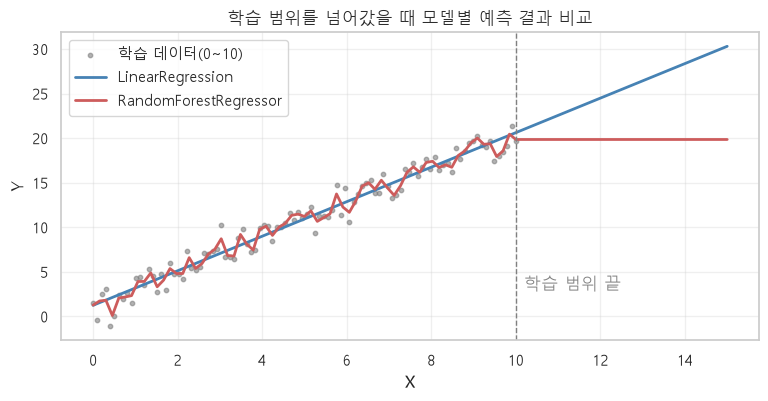

In [12]:
# 학습 데이터 범위 : 0 ~ 10
# 예측 데이터 범위 : 0 ~ 15

x_fit = np.linspace(0, 10, 100)

# y = 2x + 1 (+노이즈)
rng = np.random.default_rng(SEED)
y_fit = 2 * x_fit + 1 + rng.normal(0, 1.5, 100)

# 예측 데이터 범위 : 0 ~ 15
x_new = np.linspace(0, 15, 100)

lin_demo = LinearRegression().fit(x_fit.reshape(-1,1), y_fit)
rf_demo = RandomForestRegressor(n_estimators=100, random_state=SEED).fit(x_fit.reshape(-1,1), y_fit)

fig, ax = plt.subplots(figsize=(9, 4))

ax.scatter(x_fit, y_fit, s=10, color="gray", alpha=0.6, label="학습 데이터(0~10)")
ax.plot(x_new, lin_demo.predict(x_new.reshape(-1, 1)), color='steelblue', lw=2, label='LinearRegression')
ax.plot(x_new, rf_demo.predict(x_new.reshape(-1, 1)), color='indianred', lw=2, label='RandomForestRegressor')
ax.axvline(10, color='gray', ls='--', lw=1)
ax.text(10.2, 3, "학습 범위 끝", color='gray')

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_title("학습 범위를 넘어갔을 때 모델별 예측 결과 비교")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

랜덤 포레스트는 `x=10`을 넘어 가면 더 이상 값이 올라가지 않고 평평한 선이 됨.\
선형 회귀는 직선을 그대로 연장해서 `x=15` 에서도 실제 관계와 가까운 값을 예측함.\

랜덤 포레스트의 경우, 학습 기간에 없던 큰 변화가 들어오면 학습 때 보았던 값 근처에서만 예측을 하게 될 것임!